In [2]:
import os, json, math, copy
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando:", device)

IMG_SIZE = 48
BASE = Path("Dados/DadosFacial")   # relativo à pasta visao_comp

def resolve_root(p):
    """Desce uma pasta se existir train/train ou test/test."""
    subs = [d for d in p.iterdir() if d.is_dir()]
    if len(subs) == 1 and subs[0].name == p.name:
        return subs[0]
    return p

TRAIN_DIR = resolve_root(BASE / "train")
TEST_DIR  = resolve_root(BASE / "test")
print(TRAIN_DIR, TEST_DIR)

Usando: cuda
Dados\DadosFacial\train\train Dados\DadosFacial\test\test


In [3]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def preprocess(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return clahe.apply(img)

def load_folder(root):
    classes = sorted(d.name for d in root.iterdir() if d.is_dir())
    X, y = [], []
    for label, c in enumerate(classes):
        for f in (root / c).iterdir():
            if f.suffix.lower() in VALID_EXT:
                img = preprocess(f)
                if img is not None:
                    X.append(img)
                    y.append(label)
    return np.array(X, dtype=np.uint8), np.array(y), classes

In [4]:
X_train, y_train, class_names = load_folder(TRAIN_DIR)
X_test,  y_test,  test_classes = load_folder(TEST_DIR)
assert class_names == test_classes, f"Classes diferentes: {class_names} vs {test_classes}"
num_classes = len(class_names)

print("Classes:", class_names)
print("Treino:", dict(zip(class_names, np.bincount(y_train))))
print("Teste: ", dict(zip(class_names, np.bincount(y_test))))
print("Shape treino:", X_train.shape)

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Treino: {'angry': np.int64(3995), 'disgust': np.int64(436), 'fear': np.int64(4097), 'happy': np.int64(7215), 'neutral': np.int64(4965), 'sad': np.int64(4830), 'surprise': np.int64(3171)}
Teste:  {'angry': np.int64(958), 'disgust': np.int64(111), 'fear': np.int64(1024), 'happy': np.int64(1774), 'neutral': np.int64(1233), 'sad': np.int64(1247), 'surprise': np.int64(831)}
Shape treino: (28709, 48, 48)


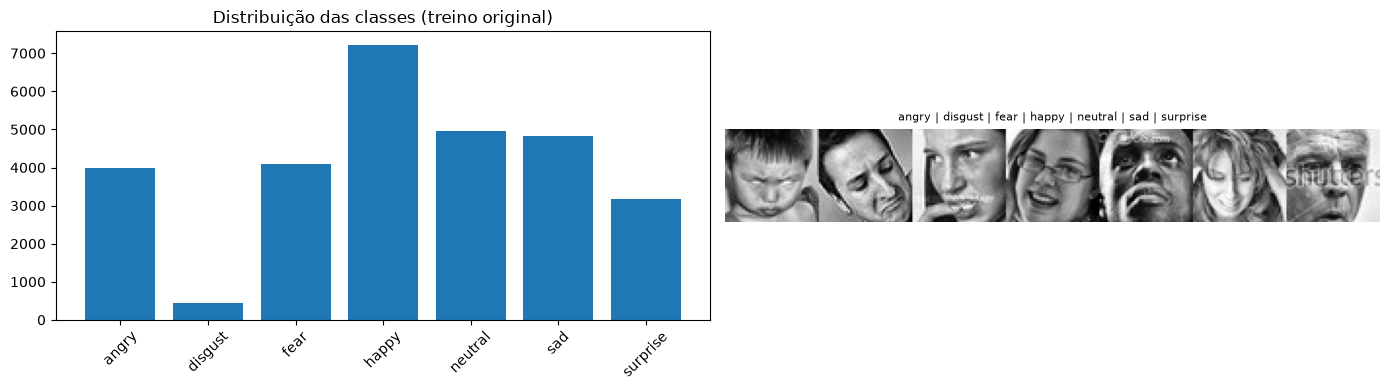

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(class_names, np.bincount(y_train))
ax[0].set_title("Distribuição das classes (treino original)")
ax[0].tick_params(axis="x", rotation=45)

exemplos = [X_train[np.where(y_train == c)[0][0]] for c in range(num_classes)]
ax[1].imshow(np.hstack(exemplos), cmap="gray")
ax[1].set_title(" | ".join(class_names), fontsize=8)
ax[1].axis("off")
plt.tight_layout()
plt.show()

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
print("Treino:", X_train.shape, "| Validação:", X_val.shape, "| Teste:", X_test.shape)

Treino: (24402, 48, 48) | Validação: (4307, 48, 48) | Teste: (7178, 48, 48)


In [7]:
def augment_cv(img):
    if rng.random() < 0.5:
        img = cv2.flip(img, 1)
    M = cv2.getRotationMatrix2D((IMG_SIZE/2, IMG_SIZE/2),
                                rng.uniform(-15, 15), rng.uniform(0.9, 1.1))
    M[:, 2] += rng.uniform(-3, 3, 2)
    img = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REPLICATE)
    return cv2.convertScaleAbs(img, alpha=rng.uniform(0.85, 1.15), beta=rng.uniform(-15, 15))

def balance(X, y, target=None):
    counts = Counter(y.tolist())
    target = target or max(counts.values())
    Xb, yb = [X], [y]
    for c, n in counts.items():
        if n < target:
            idx = np.where(y == c)[0]
            extra = rng.choice(idx, target - n, replace=True)
            Xb.append(np.array([augment_cv(X[i]) for i in extra]))
            yb.append(np.full(len(extra), c))
    Xb, yb = np.concatenate(Xb), np.concatenate(yb)
    perm = rng.permutation(len(yb))
    return Xb[perm], yb[perm]

# Se "disgust" for muito pequena, teste target=4000 em vez de None
X_train_bal, y_train_bal = balance(X_train, y_train, target=None)
print("Treino balanceado:", dict(zip(class_names, np.bincount(y_train_bal))))

Treino balanceado: {'angry': np.int64(6133), 'disgust': np.int64(6133), 'fear': np.int64(6133), 'happy': np.int64(6133), 'neutral': np.int64(6133), 'sad': np.int64(6133), 'surprise': np.int64(6133)}


In [8]:
def to_float(X):
    return (X.astype("float32") / 255.0)[:, None, :, :]   # (N, 1, 48, 48), canal primeiro

X_train_f, X_val_f, X_test_f = map(to_float, (X_train_bal, X_val, X_test))

# Média e desvio SÓ do treino
MEAN, STD = float(X_train_f.mean()), float(X_train_f.std())
X_train_f = (X_train_f - MEAN) / STD
X_val_f   = (X_val_f   - MEAN) / STD
X_test_f  = (X_test_f  - MEAN) / STD

np.savez("scaler.npz", mean=MEAN, std=STD)
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
print(f"MEAN={MEAN:.4f}  STD={STD:.4f}")

# Tensores e DataLoaders (num_workers=0 evita problemas no Windows/notebook)
BATCH = 64
train_t = TensorDataset(torch.from_numpy(X_train_f), torch.from_numpy(y_train_bal).long())
val_t   = TensorDataset(torch.from_numpy(X_val_f),   torch.from_numpy(y_val).long())
test_t  = TensorDataset(torch.from_numpy(X_test_f),  torch.from_numpy(y_test).long())

pin = device.type == "cuda"
train_loader = DataLoader(train_t, batch_size=BATCH, shuffle=True,  pin_memory=pin)
val_loader   = DataLoader(val_t,   batch_size=256,   shuffle=False, pin_memory=pin)
test_loader  = DataLoader(test_t,  batch_size=256,   shuffle=False, pin_memory=pin)

MEAN=0.5643  STD=0.2657


In [9]:
def gpu_augment(x):
    B = x.size(0)
    dev = x.device
    # espelhamento horizontal
    flip = torch.rand(B, device=dev) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    # rotação, zoom e translação via matriz afim
    angle = (torch.rand(B, device=dev) * 2 - 1) * math.radians(10)
    scale = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.1
    tx = (torch.rand(B, device=dev) * 2 - 1) * 0.08
    ty = (torch.rand(B, device=dev) * 2 - 1) * 0.08
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([
        torch.stack([cos, -sin, tx], dim=1),
        torch.stack([sin,  cos, ty], dim=1)], dim=1)          # (B, 2, 3)
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    return F.grid_sample(x, grid, padding_mode="border", align_corners=False)

In [10]:
def conv_block(in_c, out_c):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        nn.Conv2d(out_c, out_c, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout(0.25),
    )

class EmotionCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(1, 32), conv_block(32, 64),
            conv_block(64, 128), conv_block(128, 256),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = EmotionCNN(num_classes).to(device)
print(f"Parâmetros: {sum(p.numel() for p in model.parameters()):,}")

Parâmetros: 1,240,231


In [11]:
EPOCHS = 60
PATIENCE = 10

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=4, min_lr=1e-6)
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def evaluate(loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(xb)
                loss = criterion(out, yb)
            loss_sum += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return loss_sum / n, correct / n

history = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
best_acc, best_state, wait = 0.0, None, 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        xb = gpu_augment(xb)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(xb)
            loss = criterion(out, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        loss_sum += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        n += xb.size(0)

    tr_loss, tr_acc = loss_sum / n, correct / n
    va_loss, va_acc = evaluate(val_loader)
    scheduler.step(va_acc)

    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
        history[k].append(v)
    print(f"Época {epoch:02d} | loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val_loss {va_loss:.4f} val_acc {va_acc:.4f} | lr {optimizer.param_groups[0]['lr']:.1e}")

    if va_acc > best_acc:
        best_acc, wait = va_acc, 0
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, "best_model.pt")
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Early stopping.")
            break

model.load_state_dict(best_state)
print(f"Melhor val_acc: {best_acc:.4f}")

Época 01 | loss 1.6250 acc 0.3673 | val_loss 1.4469 val_acc 0.4516 | lr 1.0e-03
Época 02 | loss 1.3478 acc 0.4907 | val_loss 1.5640 val_acc 0.4411 | lr 1.0e-03
Época 03 | loss 1.2542 acc 0.5248 | val_loss 1.1882 val_acc 0.5310 | lr 1.0e-03
Época 04 | loss 1.1868 acc 0.5500 | val_loss 1.3213 val_acc 0.5117 | lr 1.0e-03
Época 05 | loss 1.1441 acc 0.5679 | val_loss 1.1941 val_acc 0.5445 | lr 1.0e-03
Época 06 | loss 1.1025 acc 0.5848 | val_loss 1.1590 val_acc 0.5649 | lr 1.0e-03
Época 07 | loss 1.0688 acc 0.5976 | val_loss 1.1698 val_acc 0.5879 | lr 1.0e-03
Época 08 | loss 1.0371 acc 0.6121 | val_loss 1.2478 val_acc 0.5598 | lr 1.0e-03
Época 09 | loss 1.0113 acc 0.6196 | val_loss 1.1084 val_acc 0.5925 | lr 1.0e-03
Época 10 | loss 0.9869 acc 0.6288 | val_loss 1.0986 val_acc 0.5997 | lr 1.0e-03
Época 11 | loss 0.9652 acc 0.6390 | val_loss 1.1082 val_acc 0.6090 | lr 1.0e-03
Época 12 | loss 0.9533 acc 0.6460 | val_loss 1.1011 val_acc 0.6013 | lr 1.0e-03
Época 13 | loss 0.9381 acc 0.6485 | val_

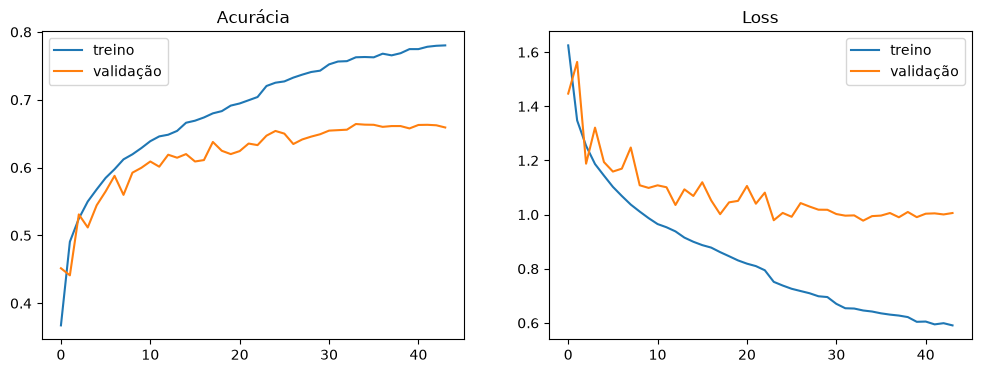

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["acc"], label="treino")
ax[0].plot(history["val_acc"], label="validação")
ax[0].set_title("Acurácia"); ax[0].legend()
ax[1].plot(history["loss"], label="treino")
ax[1].plot(history["val_loss"], label="validação")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

              precision    recall  f1-score   support

       angry       0.63      0.54      0.58       958
     disgust       0.92      0.41      0.57       111
        fear       0.53      0.43      0.47      1024
       happy       0.85      0.87      0.86      1774
     neutral       0.58      0.66      0.62      1233
         sad       0.50      0.60      0.55      1247
    surprise       0.80      0.72      0.76       831

    accuracy                           0.66      7178
   macro avg       0.69      0.61      0.63      7178
weighted avg       0.66      0.66      0.66      7178



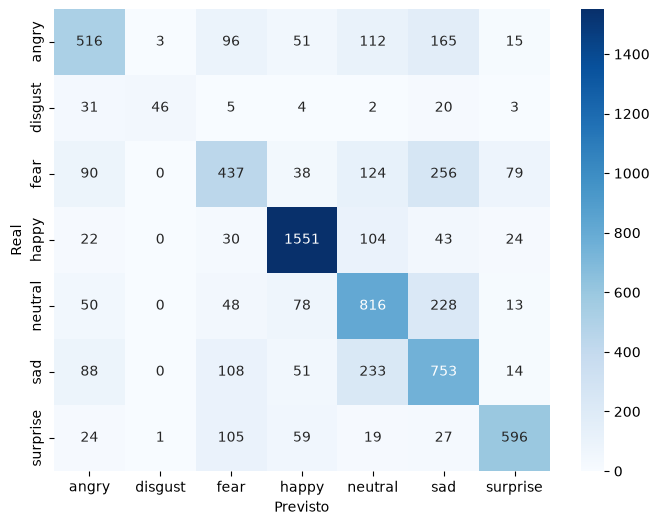

In [13]:
model.eval()
preds = []
with torch.no_grad():
    for xb, _ in test_loader:
        out = model(xb.to(device))
        preds.append(out.argmax(1).cpu().numpy())
y_pred = np.concatenate(preds)

print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Previsto"); plt.ylabel("Real")
plt.show()

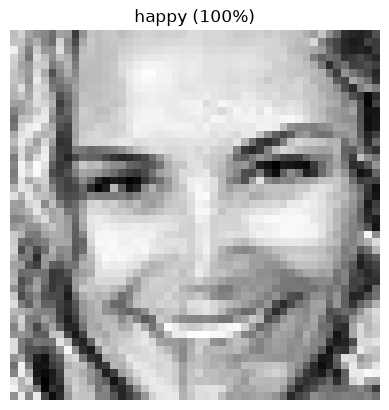

{'angry': np.float32(0.0), 'disgust': np.float32(0.0), 'fear': np.float32(0.0), 'happy': np.float32(0.995), 'neutral': np.float32(0.004), 'sad': np.float32(0.0), 'surprise': np.float32(0.0)}


In [14]:
def predict_image(path):
    img = preprocess(path)
    if img is None:
        raise ValueError(f"Não foi possível ler: {path}")
    x = ((img.astype("float32") / 255.0 - MEAN) / STD)[None, None]
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(torch.from_numpy(x).to(device)), dim=1)[0].cpu().numpy()
    plt.imshow(img, cmap="gray"); plt.axis("off")
    plt.title(f"{class_names[probs.argmax()]} ({probs.max():.0%})")
    plt.show()
    return dict(zip(class_names, probs.round(3)))

amostra = next((TEST_DIR / "happy").iterdir())
print(predict_image(amostra))